In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
GPU available: True


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [10]:
!wget -q https://data.broadinstitute.org/bbbc/BBBC038/stage1_train.zip -O dataset.zip
!unzip -q dataset.zip -d dataset

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [11]:
root_dir = "dataset"

image_ids = os.listdir(root_dir)

print("Total images:", len(image_ids))
print("Example ID:", image_ids[0])

Total images: 670
Example ID: 45f059cf21d85ecfce0eb93260516f1e2443d210e9a52f9ae2271d604aa3fcc5


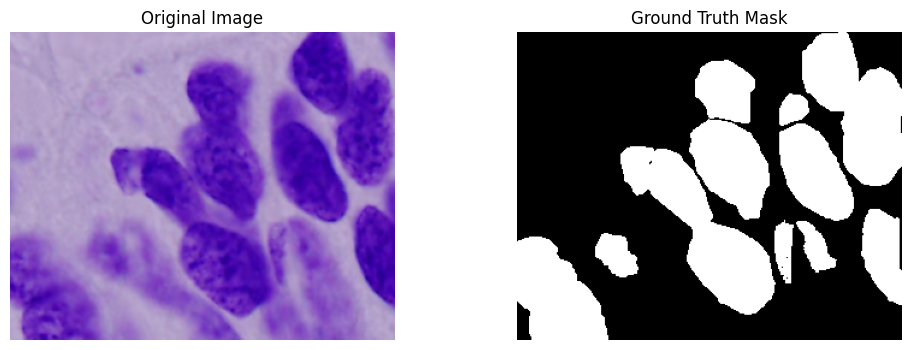

In [12]:
image_id = image_ids[0]

folder = os.path.join(root_dir, image_id)

image_file = os.listdir(os.path.join(folder, "images"))[0]

image = Image.open(
    os.path.join(folder, "images", image_file)
).convert("RGB")

mask_folder = os.path.join(folder, "masks")

mask = np.zeros((image.height, image.width), dtype=np.uint8)

for filename in os.listdir(mask_folder):
    current_mask = np.array(
        Image.open(
            os.path.join(mask_folder, filename)
        ).convert("L")
    )
    mask = np.maximum(mask, current_mask)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [13]:
class NucleiDataset(Dataset):

    def __init__(self, root_dir, image_size=256):
        self.root_dir = root_dir
        self.image_size = image_size
        self.image_ids = sorted(os.listdir(root_dir))

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):

        image_id = self.image_ids[idx]
        folder = os.path.join(self.root_dir, image_id)

        image_file = os.listdir(
            os.path.join(folder, "images")
        )[0]

        image = Image.open(
            os.path.join(folder, "images", image_file)
        ).convert("RGB")

        mask_folder = os.path.join(folder, "masks")

        mask = np.zeros(
            (image.height, image.width),
            dtype=np.uint8
        )

        for filename in os.listdir(mask_folder):

            current_mask = np.array(
                Image.open(
                    os.path.join(mask_folder, filename)
                ).convert("L")
            )

            mask = np.maximum(mask, current_mask)

        mask = Image.fromarray(mask)

        image = image.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            (self.image_size, self.image_size),
            Image.Resampling.NEAREST
        )

        image = np.array(image, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.float32) / 255.0

        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        mask = (mask > 0.5).float()

        return image, mask


dataset = NucleiDataset(root_dir, image_size=256)

print("Dataset size:", len(dataset))

Dataset size: 670


In [14]:
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 536
Validation samples: 134


In [15]:
images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)

Images shape: torch.Size([8, 3, 256, 256])
Masks shape: torch.Size([8, 1, 256, 256])


In [16]:
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

In [17]:
class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Encoder
        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        # Bottleneck
        self.bottleneck = DoubleConv(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, 2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = DoubleConv(128, 64)

        # Output
        self.out = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):

        # Encoder
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))

        # Bottleneck
        x5 = self.bottleneck(self.pool(x4))

        # Decoder + Skip Connections
        x = self.up4(x5)
        x = torch.cat([x4, x], dim=1)
        x = self.dec4(x)

        x = self.up3(x)
        x = torch.cat([x3, x], dim=1)
        x = self.dec3(x)

        x = self.up2(x)
        x = torch.cat([x2, x], dim=1)
        x = self.dec2(x)

        x = self.up1(x)
        x = torch.cat([x1, x], dim=1)
        x = self.dec1(x)

        return self.out(x)

In [18]:
model = UNet().to(device)

print(model)

UNet(
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
    )
  )
  (enc4): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(256, 512, kernel_size=(3, 3),

In [19]:
sample = torch.randn(2, 3, 256, 256).to(device)

output = model(sample)

print("Output shape:", output.shape)

Output shape: torch.Size([2, 1, 256, 256])


In [20]:
class DiceLoss(nn.Module):

    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probabilities = torch.sigmoid(logits)

        probabilities = probabilities.reshape(-1)
        targets = targets.reshape(-1)

        intersection = (probabilities * targets).sum()

        dice = (
            2.0 * intersection + self.smooth
        ) / (
            probabilities.sum() + targets.sum() + self.smooth
        )

        return 1.0 - dice


bce_loss = nn.BCEWithLogitsLoss()
dice_loss = DiceLoss()


def combined_loss(predictions, targets):

    loss_bce = bce_loss(predictions, targets)
    loss_dice = dice_loss(predictions, targets)

    return loss_bce + loss_dice

In [21]:
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5,
    min_lr=1e-6
)

In [22]:
def train_one_epoch(model, loader, optimizer, device):

    model.train()

    running_loss = 0.0
    correct_pixels = 0
    total_pixels = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        predictions = (torch.sigmoid(outputs) > 0.5).float()

        correct_pixels += (predictions == masks).sum().item()
        total_pixels += masks.numel()

    epoch_loss = running_loss / len(loader)

    accuracy = 100 * correct_pixels / total_pixels

    return epoch_loss, accuracy

In [23]:
def validate(model, loader, device):

    model.eval()

    running_loss = 0.0
    correct_pixels = 0
    total_pixels = 0

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = combined_loss(outputs, masks)

            running_loss += loss.item()

            predictions = (torch.sigmoid(outputs) > 0.5).float()

            correct_pixels += (predictions == masks).sum().item()
            total_pixels += masks.numel()

    epoch_loss = running_loss / len(loader)

    accuracy = 100 * correct_pixels / total_pixels

    return epoch_loss, accuracy

In [24]:
EPOCHS = 100

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")

patience = 15
counter = 0

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        device
    )

    scheduler.step(val_loss)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        counter = 0

        torch.save(model.state_dict(), "best_unet.pth")

    else:
        counter += 1

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Acc: {val_acc:.2f}%"
    )

    if counter >= patience:
        print("Early Stopping!")
        break

print("Best Validation Loss:", best_val_loss)

Epoch [1/100] | Train Loss: 1.0917 | Val Loss: 0.6531 | Train Acc: 86.77% | Val Acc: 90.75%
Epoch [2/100] | Train Loss: 2.4960 | Val Loss: 0.5338 | Train Acc: 89.47% | Val Acc: 91.88%
Epoch [3/100] | Train Loss: 0.6358 | Val Loss: 0.5352 | Train Acc: 90.85% | Val Acc: 91.76%
Epoch [4/100] | Train Loss: 0.5229 | Val Loss: 0.4971 | Train Acc: 92.42% | Val Acc: 92.52%
Epoch [5/100] | Train Loss: 0.5050 | Val Loss: 0.4719 | Train Acc: 92.74% | Val Acc: 92.69%
Epoch [6/100] | Train Loss: 0.4784 | Val Loss: 0.4622 | Train Acc: 93.26% | Val Acc: 92.77%
Epoch [7/100] | Train Loss: 0.4561 | Val Loss: 0.4295 | Train Acc: 93.52% | Val Acc: 93.53%
Epoch [8/100] | Train Loss: 0.4334 | Val Loss: 0.3968 | Train Acc: 93.90% | Val Acc: 94.14%
Epoch [9/100] | Train Loss: 0.4120 | Val Loss: 0.3501 | Train Acc: 94.35% | Val Acc: 95.20%
Epoch [10/100] | Train Loss: 0.3888 | Val Loss: 0.3536 | Train Acc: 94.70% | Val Acc: 95.13%
Epoch [11/100] | Train Loss: 0.3721 | Val Loss: 0.3561 | Train Acc: 94.87% | Va

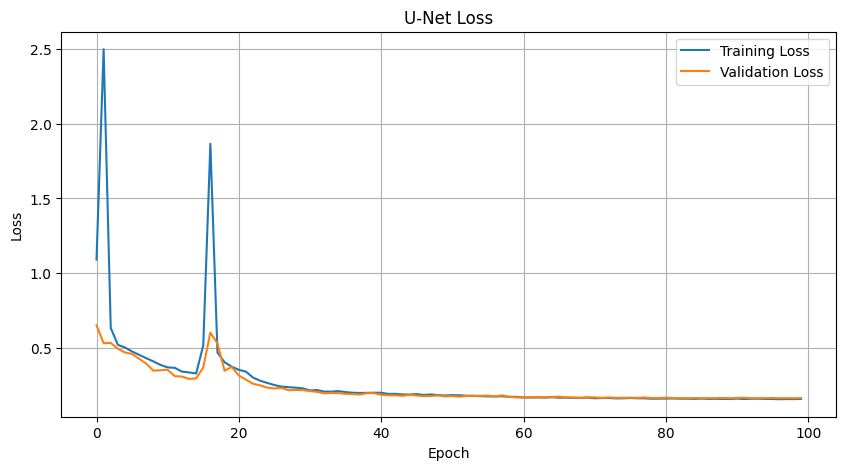

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("U-Net Loss")

plt.legend()
plt.grid()
plt.show()

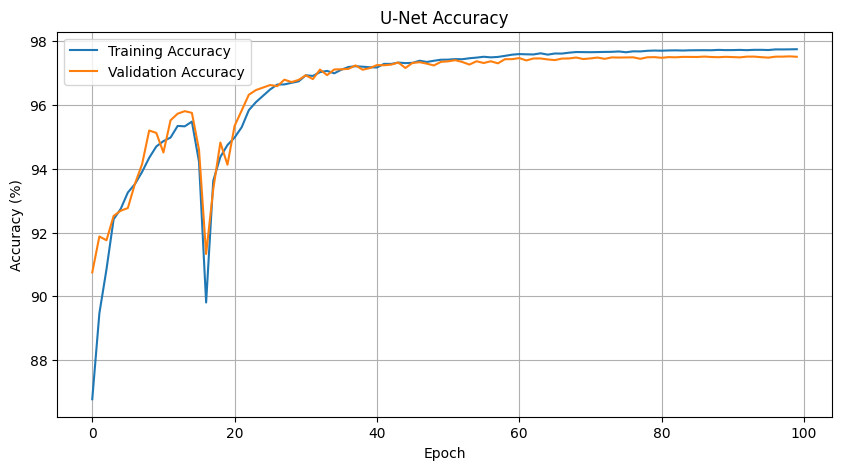

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("U-Net Accuracy")

plt.legend()
plt.grid()
plt.show()

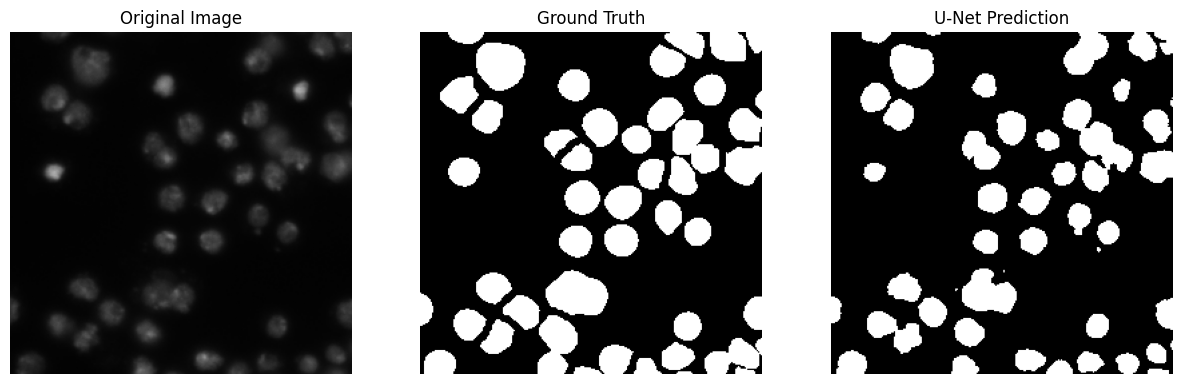

In [27]:
model.load_state_dict(
    torch.load("best_unet.pth", map_location=device)
)

model.eval()

images, masks = next(iter(val_loader))

image = images[0].unsqueeze(0).to(device)
true_mask = masks[0].squeeze().numpy()

with torch.no_grad():
    prediction = model(image)

predicted_mask = (
    torch.sigmoid(prediction) > 0.5
).float()

predicted_mask = predicted_mask.squeeze().cpu().numpy()

original_image = images[0].permute(1, 2, 0).numpy()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(true_mask, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask, cmap="gray")
plt.title("U-Net Prediction")
plt.axis("off")

plt.show()

In [28]:
def calculate_metrics(predictions, targets, smooth=1e-6):

    predictions = predictions.reshape(-1)
    targets = targets.reshape(-1)

    intersection = (predictions * targets).sum()

    dice = (
        2 * intersection + smooth
    ) / (
        predictions.sum() + targets.sum() + smooth
    )

    union = (
        predictions.sum() + targets.sum() - intersection
    )

    iou = (intersection + smooth) / (union + smooth)

    return dice.item(), iou.item()

In [29]:
model.eval()

total_dice = 0
total_iou = 0

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        predictions = (
            torch.sigmoid(outputs) > 0.5
        ).float()

        dice, iou = calculate_metrics(
            predictions,
            masks
        )

        total_dice += dice
        total_iou += iou

mean_dice = total_dice / len(val_loader)
mean_iou = total_iou / len(val_loader)

print(f"Validation Dice Score: {mean_dice:.4f}")
print(f"Validation IoU: {mean_iou:.4f}")

Validation Dice Score: 0.9157
Validation IoU: 0.8457


In [30]:
import pandas as pd

results = pd.DataFrame({
    "Metric": ["Best Validation Loss", "Dice Score", "IoU"],
    "Value": [best_val_loss, mean_dice, mean_iou]
})

display(results)

results.to_csv("unet_results.csv", index=False)

,Metric,Value
0,Best Validation Loss,0.166500
1,Dice Score,0.915722
2,IoU,0.845653


In [31]:
torch.save(model.state_dict(), "final_unet.pth")

print("Model saved successfully!")

Model saved successfully!
